170498071/170498071 [==============================] - 3s 0us/step
Epoch 1/20
79/79 [==============================] - 52s 640ms/step - loss: 2.0683 - accuracy: 0.2309 - val_loss: 1.7940 - val_accuracy: 0.3540
Epoch 2/20
79/79 [==============================] - 50s 632ms/step - loss: 1.7529 - accuracy: 0.3562 - val_loss: 1.5804 - val_accuracy: 0.4286
Epoch 3/20
79/79 [==============================] - 50s 628ms/step - loss: 1.6046 - accuracy: 0.4121 - val_loss: 1.4714 - val_accuracy: 0.4673
Epoch 4/20
79/79 [==============================] - 49s 619ms/step - loss: 1.5219 - accuracy: 0.4480 - val_loss: 1.3837 - val_accuracy: 0.5093
Epoch 5/20
79/79 [==============================] - 50s 632ms/step - loss: 1.4554 - accuracy: 0.4740 - val_loss: 1.3413 - val_accuracy: 0.5296
Epoch 6/20
79/79 [==============================] - 51s 646ms/step - loss: 1.4167 - accuracy: 0.4924 - val_loss: 1.2929 - val_accuracy: 0.5453
Epoch 7/20
79/79 [==============================] - 54s 681ms/step - loss: 

/usr/local/lib/python3.10/dist-packages/keras/src/engine/training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


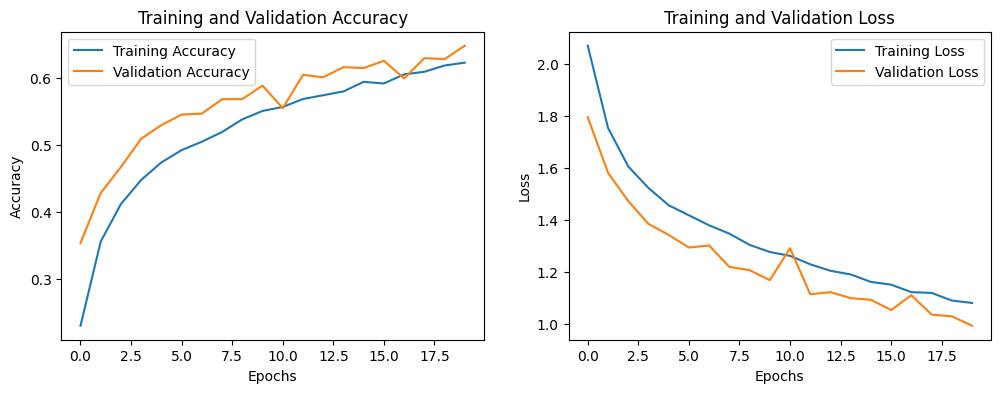

313/313 [==============================] - 4s 14ms/step - loss: 0.9946 - accuracy: 0.6456
Test loss: 0.9945673942565918
Test accuracy: 0.6456000208854675


In [2]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import matplotlib.pyplot as plt

# Load and preprocess the CIFAR-10 dataset
(cifar10_x_train, cifar10_y_train), (cifar10_x_test, cifar10_y_test) = keras.datasets.cifar10.load_data()

# Normalize pixel values to be between 0 and 1
cifar10_x_train, cifar10_x_test = cifar10_x_train / 255.0, cifar10_x_test / 255.0

# One-hot encode the labels
cifar10_y_train = keras.utils.to_categorical(cifar10_y_train, 10)
cifar10_y_test  = keras.utils.to_categorical(cifar10_y_test, 10)

# Define the CNN model
model = keras.Sequential([
    # Convolutional layers
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),

    # Flattening and Dense layers
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.5),  # Optional dropout to reduce overfitting
    layers.Dense(10, activation='softmax')  # Output layer
])

# Compile the model
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

# Train the model
history = model.fit(
    cifar10_x_train,
    cifar10_y_train,
    epochs=20,  # You can increase or decrease the number of epochs
    validation_split=0.2,  # Use 20% of the training data for validation
    batch_size=512
)


model.save("CIFAR/Cifar_epoch_15_batch_size_128.h5")
# Plot the training and validation accuracy/loss over epochs
plt.figure(figsize=(12, 4))

# Training and validation accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Training and Validation Accuracy')

# Training and validation loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Training and Validation Loss')

plt.show()

# Evaluate the model on the test set
test_loss, test_accuracy = model.evaluate(cifar10_x_test, cifar10_y_test)
print(f"Test loss: {test_loss}")
print(f"Test accuracy: {test_accuracy}")


In [1]:
import tensorflow as tf
import numpy as np
from PIL import Image
import os

# Load the saved model
model_path = "CIFAR/Cifar_epoch_15_batch_size_128.h5"
model = tf.keras.models.load_model(model_path)

# Read and preprocess the image
image_path = "/content/robot.jpeg"  # Your test image
image = Image.open(image_path)

# Resize the image to 32x32 (CIFAR-10 size)
image = image.resize((32, 32))

# Convert the image to an array and normalize
image_array = np.array(image)
image_array = image_array / 255.0  # Normalization
image_array = np.expand_dims(image_array, axis=0)  # Add batch dimension

# Predict using the model
prediction = model.predict(image_array)

# Get the class with the highest probability
predicted_class = np.argmax(prediction, axis=1)

# CIFAR-10 class names
cifar10_classes = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]

# Output the predicted class
predicted_label = cifar10_classes[predicted_class[0]]
print("Predicted class:", predicted_label)


OSError: No file or directory found at CIFAR/Cifar_epoch_15_batch_size_128.h5